In [1]:
import sys
from pathlib import Path
import numpy as np 
import pandas as pd

sys.path.append(str(Path("..").resolve()))  # dòng này thêm thưc mục gốc của project (M3-project) : đẻ python có thể đi tìm module để notebook có thể import

from src.features import load_m3
from src.baseline import make_model, GROUP_CV, log_run

df, docs, y, groups = load_m3("../data/raw/evtx_data.csv")

In [6]:
# Điểm 5 fold của cấu hình A
from sklearn.model_selection import cross_validate

LABELS = sorted(y.unique())
model_A = make_model(C=1.0)
fold_scores = cross_validate(model_A,docs,y,cv=GROUP_CV,groups=groups,scoring="f1_macro")["test_score"]
print(fold_scores.round(3)) # : in 5 điểm, làm tròn 3 chữ số.
print("macro-F1:",round(fold_scores.mean(),3),"+/-",round(fold_scores.std(),3))
log_run("A-baseline", "StratifiedGroupKFold(5,rs=42)", fold_scores, C=1.0)

[0.252 0.228 0.211 0.172 0.167]
macro-F1: 0.206 +/- 0.033


{'run_id': 'A-baseline',
 'split': 'StratifiedGroupKFold(5,rs=42)',
 'macro_f1_mean': 0.206,
 'macro_f1_std': 0.033,
 'sklearn': '1.9.1',
 'data_md5': 'f74ce83f220d5db823d1dd040170e8a4',
 'C': 1.0}

In [ ]:
# Dự đoán ngoài fold và báo cáo từng lớp
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, f1_score
oof = cross_val_predict(model_A,docs,y,cv=GROUP_CV,groups=groups)
print(len(oof), "predict")
print(classification_report(y, oof, labels=LABELS, digits=3,zero_division=0))



4633 predict
                      precision    recall  f1-score   support

 Command and Control      0.056     0.012     0.019       432
   Credential Access      0.089     0.527     0.152       283
     Defense Evasion      0.028     0.026     0.027       431
           Discovery      0.065     0.078     0.071       167
           Execution      0.078     0.047     0.059       533
    Lateral Movement      0.764     0.310     0.441      1288
         Persistence      0.321     0.345     0.333       411
Privilege Escalation      0.645     0.587     0.615      1088

            accuracy                          0.299      4633
           macro avg      0.256     0.241     0.214      4633
        weighted avg      0.417     0.299     0.319      4633



In [ ]:
# Bảng F1 từng lớp kèm số file
n_files = df.groupby("EVTX_Tactic")["EVTX_FileName"].nunique()
f1_cls = f1_score(y, oof, labels=LABELS, average=None, zero_division=0)   # F1 TỪNG lớp average=None nghĩa là không gộp. Hàm trả một mảng 8 số F1, theo đúng thứ tự LABELS.
table = pd.DataFrame({"so_file": n_files.reindex(LABELS), "F1": f1_cls.round(3)},
                     index=LABELS).sort_values("so_file") # reindex sắp lại số file theo đúng thứ tự LABELS, để khớp từng dòng với mảng F1.
print(table.to_string())

                      so_file     F1
Command and Control         5  0.019
Discovery                  10  0.071
Persistence                22  0.333
Execution                  33  0.059
Credential Access          35  0.152
Defense Evasion            36  0.027
Lateral Movement           47  0.441
Privilege Escalation       61  0.615


đã lưu ../figures/config_a_confusion.png


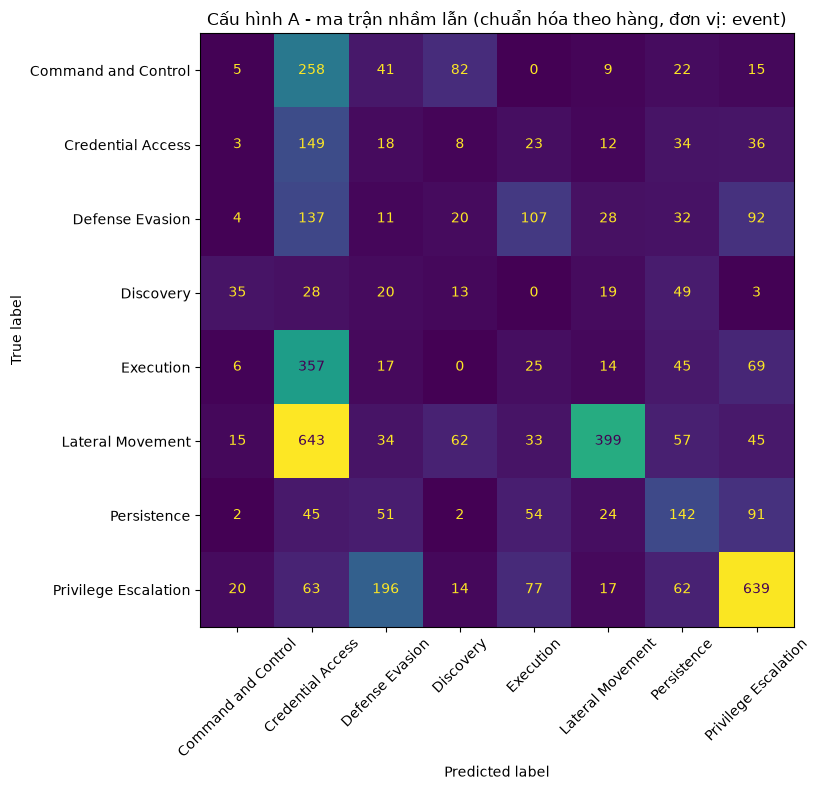

In [20]:
# Vẽ ma trận nhầm lẫn
# Đề: vẽ ma trận nhầm lẫn đủ 8 lớp, chuẩn hóa theo hàng, lưu thành hình.
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y, oof, labels=LABELS,
                                         xticks_rotation=45,
                                        ax=ax, colorbar=False)
ax.set_title("Cấu hình A - ma trận nhầm lẫn (chuẩn hóa theo hàng, đơn vị: event)")
fig.tight_layout()
fig.savefig("../figures/config_a_confusion.png", dpi=150)
print("đã lưu ../figures/config_a_confusion.png")

In [17]:
# Khoảng tin cậy: bootstrap theo file và theo event
# Đề: bootstrap 1.000 lần theo file để tính khoảng tin cậy 95% của macro-F1. Làm lại theo event (cách sai) để so sánh.
res = pd.DataFrame({"file": groups, "y": y, "pred": oof})
by_file = {f: g for f, g in res.groupby("file")}         # tra nhanh: tên file -> các event
files_all = np.array(list(by_file))
rng = np.random.default_rng(42)

def macro_f1(s):
    return f1_score(s["y"], s["pred"], labels=LABELS, average="macro", zero_division=0)

boot = []
for _ in range(1000):
    pick = rng.choice(files_all, size=len(files_all), replace=True)   # lấy lại 249 FILE
    s = pd.concat([by_file[f] for f in pick])                          # ghép event của các file đã chọn
    boot.append(macro_f1(s))
print("theo file :", np.percentile(boot, [2.5, 97.5]).round(3))

boot_e = []
for _ in range(1000):
    s = res.iloc[rng.integers(0, len(res), len(res))]                  # lấy lại EVENT (SAI)
    boot_e.append(macro_f1(s))
print("theo event:", np.percentile(boot_e, [2.5, 97.5]).round(3))

theo file : [0.151 0.243]
theo event: [0.205 0.224]


In [18]:
# Vì sao không báo điểm của C tốt nhất
# Đề: dùng GridSearchCV thử C = 0,1 / 1 / 10, in điểm từng giá trị và giá trị được chọn.
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(make_model(), {"clf__C": [0.1, 1, 10]},
                    cv=GROUP_CV, scoring="f1_macro")
grid.fit(docs, y, groups=groups)                          # BẮT BUỘC truyền groups
for C, sc in zip([0.1, 1, 10], grid.cv_results_["mean_test_score"]):
    print("C =", C, "->", round(sc, 3))
print("chọn:", grid.best_params_, round(grid.best_score_, 3))

C = 0.1 -> 0.191
C = 1 -> 0.206
C = 10 -> 0.228
chọn: {'clf__C': 10} 0.228
